# 01 — Exploratory Data Analysis

**Objective.** Understand the bank churn dataset before modelling: schema, target
balance, feature distributions, missingness and the segments most associated with
churn. All conclusions here are drawn from the *actual* files in `data/raw/`.

**Decisions this notebook justifies:** which columns are usable features, and which
identifiers must be dropped to avoid leakage.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
RAW = ROOT / "data" / "raw" / "binaryclassificationwithabankchurndataset"
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIG = MODELS / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: /home/sabina/portfolio/creditscoring


In [2]:
df = pd.read_csv(RAW / "train.csv")
print("Train shape:", df.shape)
print("Test shape :", pd.read_csv(RAW / "test.csv").shape)
display(df.head())

Train shape: (15000, 14)
Test shape : (10000, 13)


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15702656.0,Nwora,567.0,France,Male,33.0,9.0,0.0,2.0,1.0,0.0,156792.89,0.0
1,1,15647965.0,Yevdokimova,628.0,France,Female,38.0,3.0,0.0,1.0,1.0,1.0,51987.99,1.0
2,2,15798834.0,Ch'iu,635.0,France,Female,29.0,3.0,0.0,2.0,1.0,1.0,113079.19,0.0
3,3,15672056.0,Hsia,681.0,France,Male,28.0,6.0,0.0,2.0,1.0,0.0,14081.64,0.0
4,4,15759537.0,Okwudilichukwu,587.0,France,Female,27.0,5.0,0.0,2.0,1.0,0.0,158958.90,0.0


In [3]:
print("=== dtypes ===")
print(df.dtypes.to_string())
print("\n=== missing values ===")
print(df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("CustomerId unique:", df["CustomerId"].nunique(), "of", len(df))

=== dtypes ===
id                   int64
CustomerId         float64
Surname                str
CreditScore        float64
Geography              str
Gender                 str
Age                float64
Tenure             float64
Balance            float64
NumOfProducts      float64
HasCrCard          float64
IsActiveMember     float64
EstimatedSalary    float64
Exited             float64

=== missing values ===
id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0

Duplicate rows: 0
CustomerId unique: 6306 of 15000


## Target balance

`Exited = 1` means the customer left the bank (churn). The classes are imbalanced
(~20% positive), so accuracy alone will be misleading — we will track churn recall,
PR-AUC and ROC-AUC later.

,count,percent
Exited,,
0.0,12023,80.15
1.0,2977,19.85


/tmp/ipykernel_8236/506526383.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=summary.index.astype(str), y=summary["percent"], ax=ax, palette="Blues_d")


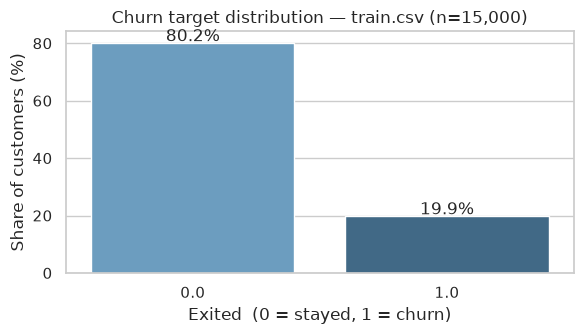

In [4]:
target = "Exited"
counts = df[target].value_counts().sort_index()
pct = (df[target].value_counts(normalize=True).sort_index() * 100).round(2)
summary = pd.DataFrame({"count": counts, "percent": pct})
display(summary)
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=summary.index.astype(str), y=summary["percent"], ax=ax, palette="Blues_d")
ax.set_title("Churn target distribution — train.csv (n=15,000)")
ax.set_xlabel("Exited  (0 = stayed, 1 = churn)")
ax.set_ylabel("Share of customers (%)")
for i, v in enumerate(summary["percent"]):
    ax.text(i, v + 0.6, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

## Numeric feature distributions

,count,mean,std,min,25%,50%,75%,max
CreditScore,15000.0,657.86,72.68,431.00,602.00,661.00,707.00,850.00
Age,15000.0,37.71,8.14,18.00,32.00,37.00,42.00,72.00
Tenure,15000.0,5.02,2.79,0.00,3.00,5.00,7.00,10.00
Balance,15000.0,42338.11,59703.05,0.00,0.00,0.00,109636.34,187911.55
NumOfProducts,15000.0,1.59,0.53,1.00,1.00,2.00,2.00,5.00
HasCrCard,15000.0,0.78,0.41,0.00,1.00,1.00,1.00,1.00
IsActiveMember,15000.0,0.50,0.50,0.00,0.00,0.00,1.00,1.00
EstimatedSalary,15000.0,116944.06,46047.49,11.58,82644.33,122449.42,155703.02,885120.79


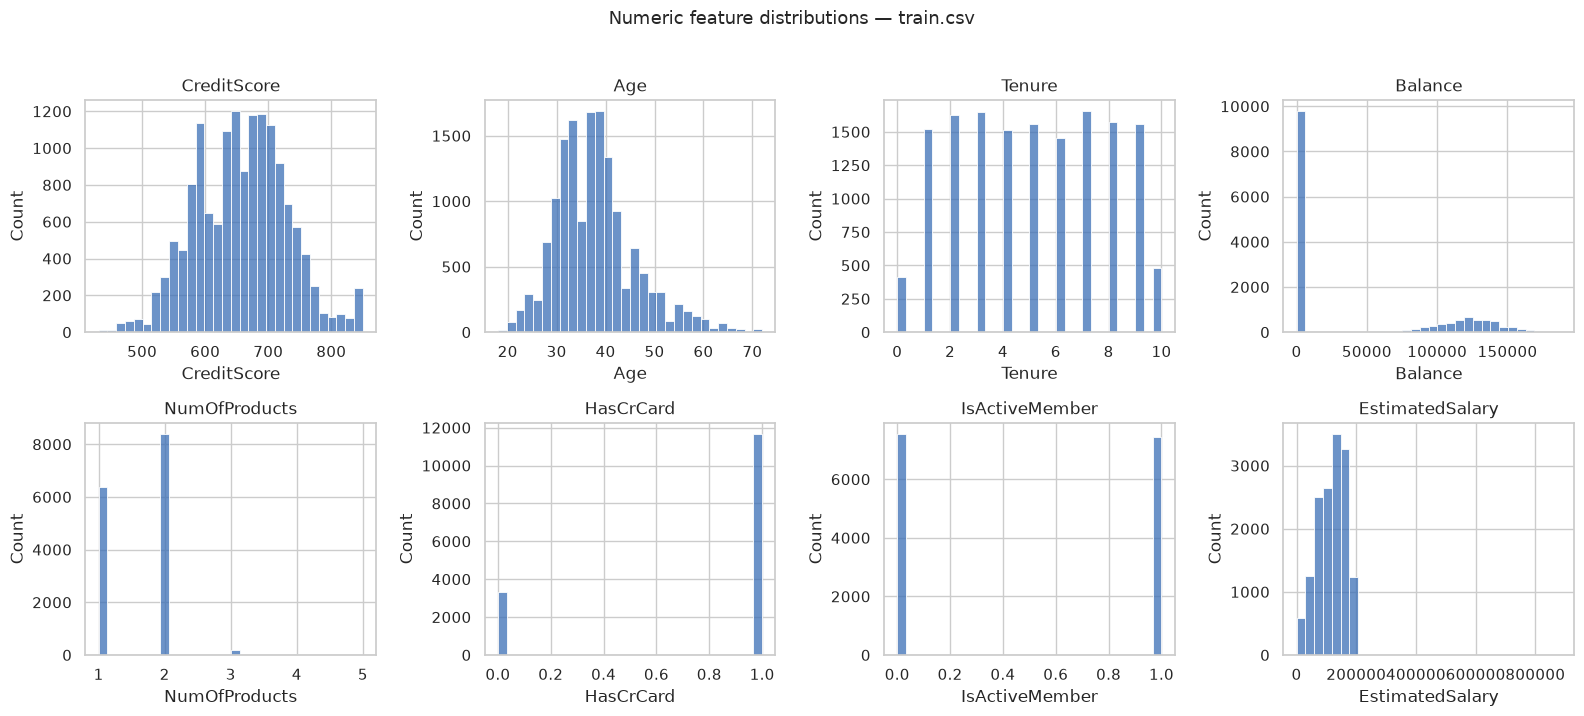

In [5]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
            "HasCrCard", "IsActiveMember", "EstimatedSalary"]
display(df[num_cols].describe().T.round(2))
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=30, ax=ax, color="#3b6fb6")
    ax.set_title(c); ax.set_xlabel(c)
plt.suptitle("Numeric feature distributions — train.csv", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

## Churn rate by segment

These plots show where churn concentrates and motivate keeping Geography, Gender,
NumOfProducts and IsActiveMember as features.

/tmp/ipykernel_8236/1338812800.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette="Blues_d")
/tmp/ipykernel_8236/1338812800.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette="Blues_d")
/tmp/ipykernel_8236/1338812800.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette="Blues_d")
/tmp/ipykernel_8236/1338812800.py:4: FutureWarning: 

Passing `palette` without assigning `

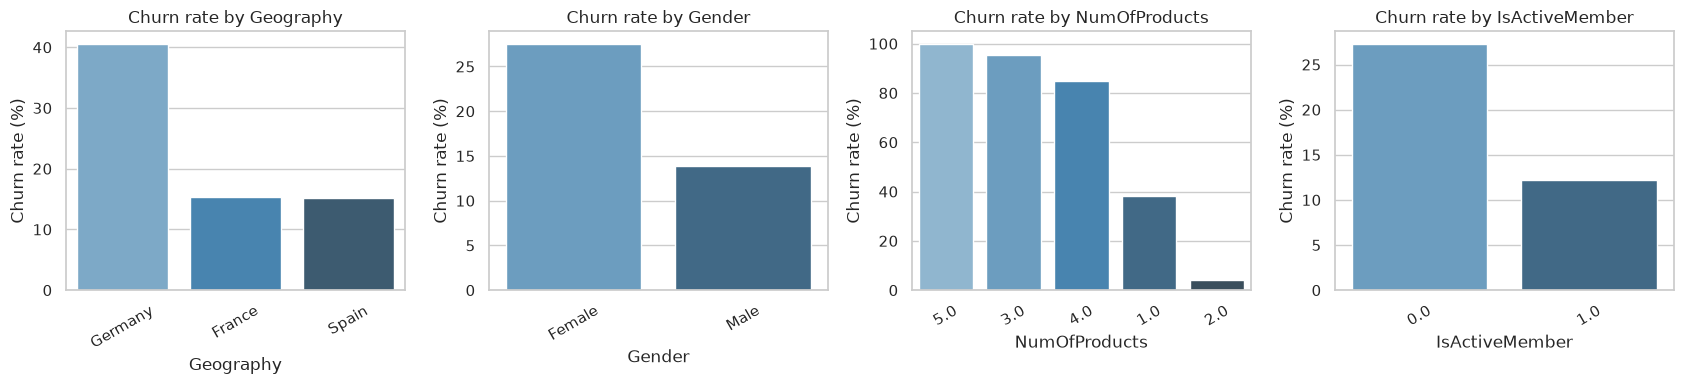

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, ["Geography", "Gender", "NumOfProducts", "IsActiveMember"]):
    rates = df.groupby(c)[target].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette="Blues_d")
    ax.set_title(f"Churn rate by {c}")
    ax.set_xlabel(c); ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## Correlation structure

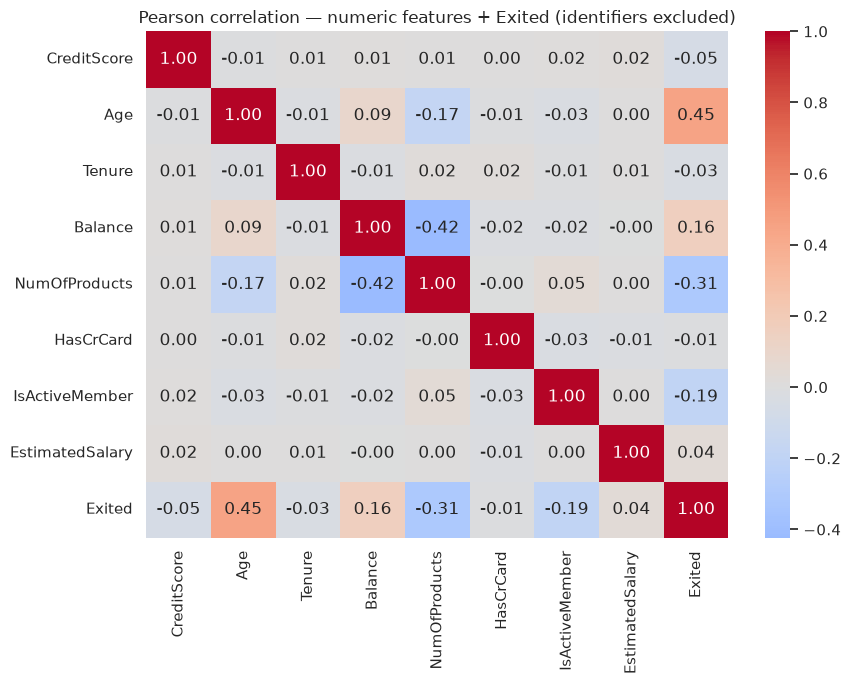

In [7]:
corr = df.drop(columns=["id", "CustomerId", "Surname"]).corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Pearson correlation — numeric features + Exited (identifiers excluded)")
plt.tight_layout(); plt.show()

## Findings & decisions

- `Exited` is imbalanced (~20% churn) → keep PR-AUC and churn recall in evaluation.
- No missing values, no duplicate rows → cleaning is minimal.
- **`id`, `CustomerId`, `Surname` are dropped**: identifiers carry no legitimate
  signal and risk leakage; `Surname` has 758 distinct values (high cardinality).
- Ten usable features remain: CreditScore, Geography, Gender, Age, Tenure, Balance,
  NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary.
- Churn concentrates in Germany, older customers, 1-product and inactive members —
  plausible, non-leaky signals worth modelling.

**Next:** 02_preprocessing — stratified split and train-only preprocessing.